# M09-1 | From Q/DQ Graph to QDQ ONNX: What `torch.onnx.export` Turns Each Op Into

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m09_onnx_runtime/01_onnx_qdq_export.ipynb)

M08 handed the Q/DQ graph to ExecuTorch; this chapter takes Route B (M07 overview): export to `.onnx` first, then hand it to ONNX Runtime (ORT). This notebook covers only the first step, the export:

```text
PT2E                              Q/DQ graph (torchao test-version XNNPACKQuantizer)
  → torch.onnx.export(dynamo=True)  ONNX ModelProto (saving it gives the .onnx)
```

- **A.** What the ONNX graph looks like: which ONNX op each PT2E op becomes.
- **B.** What the file stores: int8 weights, per-channel scales, fp32 bias; the size of the `.onnx`.
- **C.** Dynamic batch: the dynamic batch on a GraphModule is not carried into ONNX automatically.

How ORT executes this file is in M09-2.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m09_onnx_runtime")

In [2]:
import onnxruntime as ort
import torch
from onnx import numpy_helper
from torch.export import Dim

from common.pt2e import quiet  # must be imported before onnx/torchao
from common.data import trained_tiny_net
from common.env import env_summary
from common.graph_utils import op_counts
from common.models import example_inputs
from common.onnx_utils import onnx_op_counts, ort_run, ort_session, to_onnx, xnnpack_qdq
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f" | onnxruntime {ort.__version__}")

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


The model is M05's `TinyConvNet` (trained). `xnnpack_qdq` is a wrapper from this project (`common/onnx_utils.py`, not a torchao API) that does exactly the PTQ of M05-1: `export_module` (dynamic batch) → `prepare_pt2e` (torchao test-version XNNPACKQuantizer, per-channel weight) → calibration → `convert_pt2e`.

The export itself is one line, `torch.onnx.export(..., dynamo=True)`. It re-runs `torch.export` on `x`, then translates each ATen op into an ONNX op; what `dynamic_shapes` is for is covered in section C.

In [3]:
model = trained_tiny_net()
x = example_inputs()                                       # batch 2
qdq = xnnpack_qdq(model, x)                                # Q/DQ graph
program = torch.onnx.export(qdq, x, dynamo=True, verbose=False, dynamic_shapes=({0: Dim("batch")},))
assert program is not None
onnx_model = program.model_proto                           # QDQ ONNX
print(f"QDQ ONNX: {len(onnx_model.graph.node)} nodes, {len(onnx_model.graph.initializer)} initializers")

QDQ ONNX：41 個 node、31 個 initializer


This project wraps that line as `to_onnx(gm, x)` (`common/onnx_utils.py`), which the later notebooks use.

## A. What the ONNX Graph Looks Like

Start with the first conv unit. `draw_onnx` is this project's tool for drawing ONNX graphs (`common/viz.py`), used like the `draw` that drew fx graphs in earlier chapters: the second line of a node is the ONNX node's name, `‹…›` holds constants stored in the file, and scale and zero point are printed under Q/DQ.

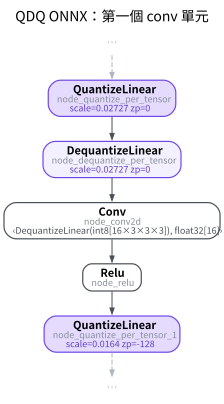

In [4]:
draw_onnx(onnx_model, focus="node_conv2d", hops=2, title="QDQ ONNX: first conv unit")

It is identical to the Q/DQ graph seen in M01, just renamed: `quantize_per_tensor` → `QuantizeLinear`, `dequantize_per_tensor` → `DequantizeLinear`, `conv2d` → `Conv`. The `DequantizeLinear(int8[…])` on the weight side takes only constants, so it is folded into the Conv's label.

The correspondence for the whole graph:

In [5]:
PT2E_TO_ONNX = [
    ("quantize_per_tensor", "QuantizeLinear", "activation fp32 → int8"),
    ("dequantize_per_tensor", "DequantizeLinear", "activation int8 → fp32"),
    ("dequantize_per_channel", "DequantizeLinear", "weight int8 → fp32; axis=0: one scale per output channel"),
    ("conv2d", "Conv", ""),
    ("relu", "Relu", ""),
    ("max_pool2d", "MaxPool", ""),
    ("add", "Add", ""),
    ("adaptive_avg_pool2d", "ReduceMean", "adaptive pool with 1×1 output equals the mean over H, W"),
    ("flatten", "Reshape", ""),
    ("linear", "Gemm", ""),
]
pc, oc = op_counts(qdq), onnx_op_counts(onnx_model)
rows = [[p, pc.get(p, 0), o, oc.get(o, 0), note] for p, o, note in PT2E_TO_ONNX]
rows[2][2:4] = ["↑ (same as above)", ""]  # both kinds of dq become DequantizeLinear; the combined count is in the previous row
table(rows, ["Q/DQ graph op", "Count", "ONNX op", "Count", "Note"])

Q/DQ 圖的 op,個數,ONNX op,個數,說明
quantize_per_tensor,11,QuantizeLinear,11,activation 的 fp32 → int8
dequantize_per_tensor,12,DequantizeLinear,16,activation 的 int8 → fp32
dequantize_per_channel,5,↑（同上）,,weight 的 int8 → fp32；axis=0：每個輸出 channel 一組 scale
conv2d,4,Conv,4,
relu,4,Relu,4,
max_pool2d,2,MaxPool,2,
add,1,Add,1,
adaptive_avg_pool2d,1,ReduceMean,1,輸出 1×1 的 adaptive pool 等於對 H、W 取平均
flatten,1,Reshape,1,
linear,1,Gemm,1,


Each op becomes a standard ONNX op one-to-one, and the Q/DQ positions are unchanged. This style is called the **QDQ format**: all quantization information sits on `QuantizeLinear` / `DequantizeLinear`, while the compute ops themselves are still the fp32 `Conv` and `Gemm`.

Only one number does not match: there are fewer `DequantizeLinear` than the two kinds of dq in the Q/DQ graph added together. Look near the residual `Add`:

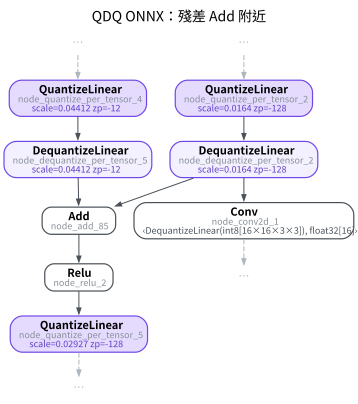

In [6]:
draw_onnx(onnx_model, focus=lambda n: n.op_type == "Add", hops=2, title="QDQ ONNX: around the residual Add")

In [7]:
n_dq = pc["dequantize_per_tensor"] + pc["dequantize_per_channel"]
print(f"dq in the Q/DQ graph: {n_dq}; DequantizeLinear in the QDQ ONNX: {oc['DequantizeLinear']}")
assert oc["DequantizeLinear"] < n_dq

Q/DQ 圖的 dq：17 個；QDQ ONNX 的 DequantizeLinear：16 個


The `DequantizeLinear` on the right feeds both the `Add` and the next `Conv`. From the Q/DQ graph to ORT, this dq is duplicated, merged, and duplicated again, and the three steps are done by three different tools:

| Step | Why |
|---|---|
| **Duplicate**: `DuplicateDQPass` in `convert_pt2e` (M02-3) makes one copy for each user | The Q/DQ graph does not know which backend it will go to, so it is written uniformly with a complete dq → op → q around every op, letting the backend match unit by unit and swap in int8 kernels |
| **Merge**: `torch.onnx.export`'s default graph optimization | A generic cleanup (onnxscript's `CommonSubexpressionEliminationPass`) that knows nothing about QDQ: two nodes with the same op and inputs are treated as duplicate computation |
| **Duplicate again**: when ORT creates the session (M09-2) | ORT also looks for kernels in units of DQ → op → Q, so before any graph optimization it uses `EnsureUniqueDQForNodeUnit` to give each unit its own DQ back |

The party that needs "each unit has its own dq" is the one looking for kernels; the merge in between is just the export tool not knowing about this need.

To confirm in code that the merge comes from `torch.onnx.export`'s graph optimization: turn it off with `torch.onnx.export(Q/DQ graph, x, dynamo=True, optimize=False)` (`to_onnx(..., optimize=False)`), and the number of DequantizeLinear equals the number of dq in the Q/DQ graph:

In [8]:
n_raw = onnx_op_counts(to_onnx(qdq, x, optimize=False))["DequantizeLinear"]
print(f"With torch.onnx.export graph optimization off: {n_raw} DequantizeLinear ({n_dq} dq in the Q/DQ graph)")
assert n_raw == n_dq

關掉 torch.onnx.export 的圖最佳化：DequantizeLinear 17 個（Q/DQ 圖的 dq 17 個）


The two merged dq have identical inputs and parameters, so the output is the same whether or not they are merged; ORT splits them again by itself, so the rest of this chapter exports with the default `optimize=True` as usual.

## B. What the File Stores

ONNX stores constants as **initializers**. Grouped by purpose:

In [9]:
def role(op_type, idx):
    """The initializer is input number idx of some op -> its purpose."""
    if op_type == "DequantizeLinear":
        return ["weight (int8)", "weight per-channel scale", "weight zero_point"][idx]
    if op_type in ("Conv", "Gemm") and idx == 2:
        return "conv/linear bias"
    return {"ReduceMean": "ReduceMean axes", "Reshape": "Reshape target shape"}.get(op_type, f"{op_type} parameter")


roles = {}
for n in onnx_model.graph.node:
    for idx, name in enumerate(n.input):
        roles.setdefault(name, role(n.op_type, idx))
groups, n_scalar = {}, 0
for init in onnx_model.graph.initializer:
    arr = numpy_helper.to_array(init)
    if arr.size == 1:
        n_scalar += 1
        continue
    g = groups.setdefault(roles[init.name], [str(arr.dtype), 0, []])
    g[1] += 1
    g[2].append("×".join(map(str, arr.shape)))
rows = [[r, dt, cnt, ", ".join(shapes[:3]) + ("…" if len(shapes) > 3 else "")] for r, (dt, cnt, shapes) in groups.items()]
rows.append(["activation scale/zero_point", "float32/int8", n_scalar, "scalar"])
table(rows, ["Purpose", "dtype", "Count", "shape"])

用途,dtype,個數,shape
conv／linear 的 bias,float32,5,16、16、16…
weight（int8）,int8,5,16×3×3×3、16×16×3×3、16×16×3×3…
weight 的 per-channel scale,float32,5,16、16、16…
weight 的 zero_point,int8,3,16、32、4
ReduceMean 的 axes,int64,1,2
Reshape 的目標 shape,int64,1,2
activation 的 scale／zero_point,float32／int8,11,純量


In [10]:
assert groups["weight (int8)"][0] == "int8" and groups["conv/linear bias"][0] == "float32"

- The int8 weights are constants that `convert_pt2e` has already quantized (M02-3), written into the file as they are; one scale per output channel.
- The weights are symmetrically quantized, so every zero point is 0; zero points with identical content are stored once (shared by weights with the same channel count), so there are fewer of them than weights.
- The bias is not quantized in the Q/DQ graph, so it is still float32 in the file.

The file holds int8 weights, but **the file itself contains no int8 kernel**: `Conv` is still an fp32 op, and whether it is replaced by an int8 kernel is decided by the ORT that runs it (M09-2).

Export the fp32 model too, and compare the sizes of the two files piece by piece:

In [11]:
def sizes(name, m):
    """(total .onnx size, initializer, node, of which node metadata_props), in bytes."""
    init = sum(len(i.SerializeToString()) for i in m.graph.initializer)
    nodes = sum(len(n.SerializeToString()) for n in m.graph.node)
    meta = sum(len(p.SerializeToString()) + 2 for n in m.graph.node for p in n.metadata_props)
    return [name, len(m.SerializeToString()), init, nodes, meta]


rows = [sizes("torch.onnx.export(fp32 model) (to_onnx)", to_onnx(model, x)), sizes("torch.onnx.export(Q/DQ graph)", onnx_model)]
table(rows, ["", "Total", "initializer", "node", "metadata_props in nodes"])

,總計,initializer,node,node 裡的 metadata_props
torch.onnx.export(fp32 模型)（to_onnx）,59195,39795,15693,13995
torch.onnx.export(Q/DQ 圖),66019,11112,47638,42519


In [12]:
init_ratio, total_ratio = rows[1][2] / rows[0][2], rows[1][1] / rows[0][1]
print(f"Initializers are {init_ratio:.0%} of fp32; total file size is {total_ratio:.0%} of fp32")
if total_ratio > 1:
    print("The file actually grows: the extra QuantizeLinear/DequantizeLinear nodes each carry their own metadata_props.")
assert init_ratio < 0.5

initializer 變成 fp32 的 28%；檔案總大小是 fp32 的 112%
檔案反而變大：多出來的 QuantizeLinear／DequantizeLinear node，各帶一份 metadata_props。


Weights go from 4 bytes to 1 byte, so the initializers shrink a lot. But `torch.onnx.export` writes provenance information (the original fx node, the module path) into each node's `metadata_props`, and Q/DQ adds a pile of nodes; in this small model the nodes take more space than the weights. The larger the model, the higher the weights' share (an inference; no larger model was measured).

## C. Dynamic Batch

The first step of the Q/DQ graph is `torch.export.export(..., dynamic_shapes=({0: Dim.AUTO},))` (wrapped in `export_module`), so the batch dimension is dynamic. Export the same Q/DQ graph twice, differing only in whether `dynamic_shapes` is passed; create one `ort.InferenceSession` for each (`ort_session`) and feed two batch sizes:

In [13]:
rows, dim0 = [], {}
for dynamic in [False, True]:
    m = to_onnx(qdq, x, dynamic_batch=dynamic)
    d = m.graph.input[0].type.tensor_type.shape.dim[0]
    dim0[dynamic] = d.dim_param or d.dim_value
    sess = ort_session(m)
    results = []
    for bs in [x[0].shape[0], 4]:
        try:
            ort_run(sess, torch.randn(bs, 3, 16, 16))
            results.append(f"batch {bs} OK")
        except Exception as e:  # ORT's shape error is InvalidArgument
            results.append(f"batch {bs} {type(e).__name__}")
    rows.append(['dynamic_shapes=({0: Dim("batch")},)' if dynamic else "no dynamic_shapes", dim0[dynamic], "; ".join(results)])
table(rows, ["torch.onnx.export(Q/DQ graph, x, dynamo=True, …)", "Input dim 0", "ORT run"])

"torch.onnx.export(Q/DQ 圖, x, dynamo=True, …)",輸入的第 0 維,ORT 執行
不傳 dynamic_shapes,2,batch 2 OK；batch 4 InvalidArgument
"dynamic_shapes=({0: Dim(""batch"")},)",batch,batch 2 OK；batch 4 OK


In [14]:
assert dim0[False] == x[0].shape[0] and isinstance(dim0[True], str)

`torch.onnx.export(dynamo=True)` re-runs `torch.export` on `x`, so without `dynamic_shapes` dimension 0 is hard-coded to `x`'s batch, and the GraphModule's original dynamic batch is not carried over. With `dynamic_shapes`, dimension 0 becomes a symbol and ORT accepts any batch. The rest of this chapter exports this way (`to_onnx` defaults to `dynamic_batch=True`).

## Summary

- After export to ONNX the Q/DQ graph keeps its structure: q/dq become `QuantizeLinear` / `DequantizeLinear`, and the other ops become standard ONNX ops. This is the QDQ format.
- In the file, weights are int8 + per-channel scale and the bias is still fp32; the file contains no int8 kernel yet.
- Dynamic batch has to be stated again in `torch.onnx.export`.
- Whether "DequantizeLinear → Conv → QuantizeLinear" is replaced by an int8 kernel is decided by the ORT that runs it (M09-2).